# 05 — Verdieping: XGBoost (classifier én regressor)

Deze notebook hoort bij [`docs/methodologie/xgboost.md`](../docs/methodologie/xgboost.md)
en [`docs/methodologie/individueel.md`](../docs/methodologie/individueel.md).
XGBoost wordt op twee manieren ingezet:

| Rol | Spoor | Input | Output |
|-----|-------|-------|--------|
| **Classifier** | Individueel (`-d i`) | aanmeldingen per student | kans dat één student zich inschrijft |
| **Regressor** | Cumulatief (`-d c`) | aanmeldcurve per opleiding | verwacht aantal eerstejaars |

We bouwen vereenvoudigde, werkende versies van beide en vergelijken met de pipeline.


> 🧭 **Verdieping: een ander spoor.** Het aanbevolen model is het
> [CWF-model](02_cwf_model.ipynb): het is doorgaans nauwkeuriger en
> geeft er een onzekerheidsmarge en betrouwbaarheidslabel bij. Deze notebook legt
> een van de andere sporen uit. Die zijn nog steeds te gebruiken (`-d c`, `-d i`,
> `-d b`), bijvoorbeeld om te vergelijken.


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


## DEEL A — Classifier (individueel spoor)

### A.1 Data en label

Deel A gebruikt de **individuele aanmelddata**. Die zit niet in de repo; je krijgt hem
met `studentprognose init` (kies "j" bij de demodata). De helper zoekt in
`data/input/vooraanmeldingen_individueel.csv` en `data/input_raw/individuele_aanmelddata.csv`.

Elke aanmelding krijgt een label: **1** = ingeschreven, **0** = niet ingeschreven.


In [2]:
from _helpers import load_individueel

ind = load_individueel(n_sample=None)
if ind is None:
    raise FileNotFoundError(
        "Geen individuele aanmelddata gevonden. Draai `studentprognose init` in de "
        "projectmap en kies 'j' bij de demodata, of sla deel A over."
    )
print(f"Aanmeldingen:  {len(ind):,}")
print(f"Opleidingen:   {ind['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:  {ind['Collegejaar'].min()}–{ind['Collegejaar'].max()}")

INGESCHREVEN_STATUSSEN = {"Ingeschreven", "Uitgeschreven"}
ind = ind.dropna(subset=["Inschrijfstatus", "Croho groepeernaam", "Examentype"]).copy()
ind["label"] = ind["Inschrijfstatus"].isin(INGESCHREVEN_STATUSSEN).astype(int)
print(f"Deel dat zich inschrijft: {ind['label'].mean():.1%}  (de naïeve voorspelling)")


Aanmeldingen:  53,603
Opleidingen:   18
Collegejaren:  2016–2024
Deel dat zich inschrijft: 67.6%  (de naïeve voorspelling)


### A.2 Trainen en voorspellen

We trainen op alle jaren behalve het laatste en voorspellen het laatste jaar.
`n_estimators=200`, `max_depth=4` (ondiepe bomen, minder overfitting),
`learning_rate=0.1`.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

cat_features = [c for c in ["Examentype", "Faculteit", "Croho groepeernaam", "EER",
                            "Type vooropleiding", "Nationaliteit", "Geslacht"] if c in ind.columns]
num_features = ["Collegejaar"]

LAATSTE_JAAR = int(ind["Collegejaar"].max())
train = ind[ind["Collegejaar"] < LAATSTE_JAAR]
test = ind[ind["Collegejaar"] == LAATSTE_JAAR]

clf = SkPipeline([
    ("pre", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ("num", "passthrough", num_features),
    ])),
    ("xgb", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                          random_state=42, eval_metric="logloss", n_jobs=2)),
])
X_train = train[cat_features + num_features].astype({c: str for c in cat_features}).fillna("ONBEKEND")
X_test = test[cat_features + num_features].astype({c: str for c in cat_features}).fillna("ONBEKEND")
clf.fit(X_train, train["label"])
proba = clf.predict_proba(X_test)[:, 1]

verwacht, werkelijk = float(proba.sum()), float(test["label"].sum())
print(f"Testjaar:  {LAATSTE_JAAR} ({len(test):,} aanmeldingen)")
print(f"Accuracy:  {accuracy_score(test['label'], proba >= 0.5):.3f}  (naïef: {max(test['label'].mean(), 1 - test['label'].mean()):.3f})")
print(f"AUC-ROC:   {roc_auc_score(test['label'], proba):.3f}  (1,0 = perfect, 0,5 = gokken)")
print(f"Cohort:    verwacht {verwacht:.0f}, werkelijk {werkelijk:.0f} ({(verwacht - werkelijk) / werkelijk:+.1%})")


Testjaar:  2024 (6,387 aanmeldingen)
Accuracy:  0.673  (naïef: 0.674)
AUC-ROC:   0.486  (1,0 = perfect, 0,5 = gokken)
Cohort:    verwacht 4370, werkelijk 4306 (+1.5%)


> 📌 **Over de AUC:** de demodata is synthetisch en de beschikbare kenmerken zeggen
> weinig over wie zich inschrijft. Met echte data (vooropleiding, cijfers,
> studiekeuzecheck) ligt de AUC doorgaans hoger. Waar het om gaat is het
> **cohort**: de som van de kansen.

### A.3 Van kans per student naar cohort

Voor een opleiding tel je de kansen op. Dat is precies wat de pipeline doet.


In [4]:
t = test.assign(kans=proba)
per_opleiding = (
    t.groupby("Croho groepeernaam")
    .agg(verwacht=("kans", "sum"), werkelijk=("label", "sum"), aanmeldingen=("label", "size"))
    .round(0)
)
per_opleiding["fout_%"] = ((per_opleiding["verwacht"] - per_opleiding["werkelijk"])
                           / per_opleiding["werkelijk"].replace(0, np.nan) * 100).round(1)
per_opleiding.sort_values("werkelijk", ascending=False).head(10)


,verwacht,werkelijk,aanmeldingen,fout_%
Croho groepeernaam,,,,
B Psychologie,609.0,573,843,6.3
B Geneeskunde,492.0,558,770,-11.8
B Kunstmatige Intelligentie,483.0,456,733,5.9
B Bedrijfskunde,424.0,412,611,2.9
B Biomedische Wetenschappen,281.0,302,423,-7.0
B Communicatiewetenschap,249.0,249,351,0.0
B Politicologie,253.0,234,359,8.1
B Geschiedenis,202.0,177,284,14.1
B Wiskunde,170.0,177,257,-4.0


## DEEL B — Regressor (cumulatief spoor)

### B.1 Kenmerken

De regressor leert per opleiding × herkomst × examentype × jaar op basis van de
aanmeldcurve tot de peilweek, plus een paar afgeleide kenmerken:

| Type | Kenmerken |
|------|-----------|
| **Weken** | gewogen vooraanmelders per week tot de peilweek |
| **Vertraagd** | `Gewogen_t-2`, `Gewogen_t-5` |
| **Versnelling** | `(huidig − t-2) − (t-2 − t-5)` |
| **Exclusiviteit** | `exclusivity_ratio` = aanmelders met één aanmelding / alle aanmelders (in de demodata altijd 0) |
| **Categorisch** | `Examentype`, `Croho groepeernaam`, `Herkomst` |


In [5]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


In [6]:
from studentprognose.data.transforms import transform_data
from studentprognose.utils.weeks import get_all_weeks_valid

PREDICT_WEEK = 12
SLEUTELS = ["Collegejaar", "Faculteit", "Herkomst", "Examentype", "Croho groepeernaam"]

df = data_cumulative[data_cumulative["Collegejaar"] >= 2018]
wide = transform_data(df, "Gewogen vooraanmelders")
feature_weeks = [w for w in get_all_weeks_valid(wide.columns) if 1 <= int(w) <= PREDICT_WEEK]

for lag in (2, 5):
    ref = (
        df[df["Weeknummer"] == max(PREDICT_WEEK - lag, 1)]
        .groupby(SLEUTELS)["Gewogen vooraanmelders"].sum()
        .rename(f"Gewogen_t-{lag}").reset_index()
    )
    wide = wide.merge(ref, on=SLEUTELS, how="left")
wide["Gewogen_acceleration"] = (
    (wide[str(PREDICT_WEEK)] - wide["Gewogen_t-2"]) - (wide["Gewogen_t-2"] - wide["Gewogen_t-5"])
)

# Exclusiviteit: welk deel van de aanmelders zich alleen voor deze opleiding aanmeldde
peil = df[df["Weeknummer"] == PREDICT_WEEK].groupby(SLEUTELS)[
    ["Aantal aanmelders met 1 aanmelding", "Ongewogen vooraanmelders"]].sum()
peil["exclusivity_ratio"] = peil["Aantal aanmelders met 1 aanmelding"] / (peil["Ongewogen vooraanmelders"] + 1e-8)
wide = wide.merge(peil[["exclusivity_ratio"]].reset_index(), on=SLEUTELS, how="left")
print(f"Kenmerkenmatrix: {wide.shape[0]} rijen × {wide.shape[1]} kolommen")


Kenmerkenmatrix: 3617 rijen × 51 kolommen


### B.2 Trainen en testen

We trainen op alle jaren vóór het laatste jaar met realisatie en testen op dat jaar.


In [7]:
from xgboost import XGBRegressor

training = wide.merge(
    data_studentcount.rename(columns={"Aantal_studenten": "y"})[
        ["Collegejaar", "Croho groepeernaam", "Herkomst", "Examentype", "y"]],
    on=["Collegejaar", "Croho groepeernaam", "Herkomst", "Examentype"], how="inner",
).dropna(subset=["y"])

LATEST = int(training["Collegejaar"].max())
train_xgb = training[training["Collegejaar"] < LATEST].copy()
test_xgb = training[training["Collegejaar"] == LATEST].copy()

cat_r = ["Examentype", "Croho groepeernaam", "Herkomst"]
num_r = feature_weeks + ["Gewogen_t-2", "Gewogen_t-5", "Gewogen_acceleration", "exclusivity_ratio", "Collegejaar"]
reg = SkPipeline([
    ("pre", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_r),
        ("num", "passthrough", num_r),
    ])),
    ("xgb", XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42, n_jobs=2)),
])
X_tr = train_xgb[cat_r + num_r].astype({"Croho groepeernaam": str}).fillna(0)
X_te = test_xgb[cat_r + num_r].astype({"Croho groepeernaam": str}).fillna(0)
reg.fit(X_tr, train_xgb["y"])
preds = reg.predict(X_te)

wape = float(np.abs(preds - test_xgb["y"]).sum() / test_xgb["y"].sum())
print(f"Trainjaren: {sorted(int(j) for j in train_xgb['Collegejaar'].unique())}")
print(f"Testjaar:   {LATEST} ({len(test_xgb)} rijen)")
print(f"WAPE:       {wape:.1%}")


Trainjaren: [2020, 2021, 2022, 2023, 2024]
Testjaar:   2025 (512 rijen)
WAPE:       18.3%


### B.3 Welke kenmerken tellen?

XGBoost geeft per (one-hot) kenmerk een score. We tellen die per oorspronkelijke kolom
op, zoals de pipeline dat ook doet.


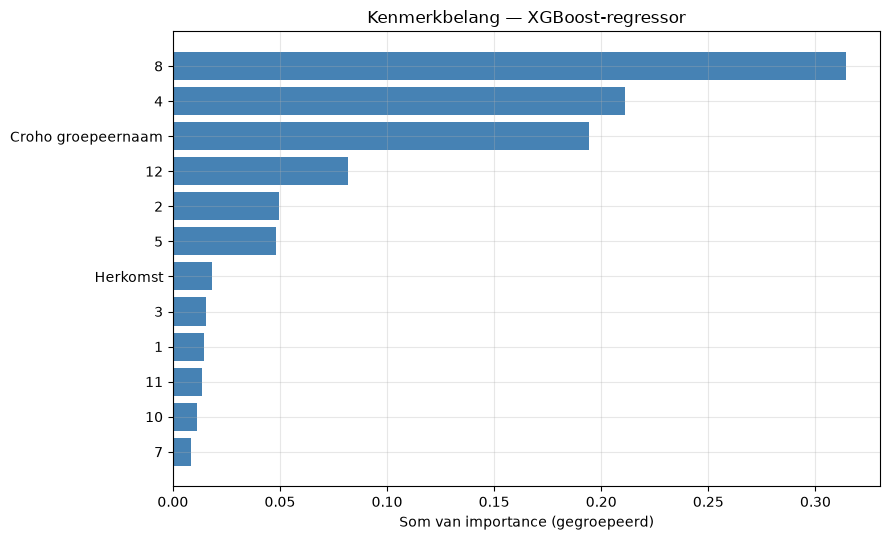

In [8]:
namen_enc = reg.named_steps["pre"].get_feature_names_out()
records = []
for naam, imp in zip(namen_enc, reg.named_steps["xgb"].feature_importances_):
    kaal = naam.split("__", 1)[1] if "__" in naam else naam
    basis = next((c for c in cat_r if kaal.startswith(c + "_")), kaal)
    records.append({"kenmerk": basis, "importance": imp})

imp_df = (pd.DataFrame(records).groupby("kenmerk", as_index=False)["importance"].sum()
          .sort_values("importance").tail(12))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp_df["kenmerk"], imp_df["importance"], color="steelblue")
ax.set_xlabel("Som van importance (gegroepeerd)")
ax.set_title("Kenmerkbelang — XGBoost-regressor")
plt.tight_layout()
plt.show()


### B.4 Vergelijking met de pipeline en het CWF-model

We draaien de cumulatieve pipeline (SARIMA + XGBoost) en het CWF-model voor
hetzelfde jaar en dezelfde peilweek, op een selectie van de grootste opleidingen.


In [9]:
from _helpers import grootste_opleidingen

# De cumulatieve pipeline (SARIMA + XGBoost) is zwaar: hij fit een tijdreeks per
# opleiding × herkomst. Voor de snelheid draaien we hem hier op de grootste
# bachelors. Zet SELECTIE = [] om alle opleidingen te voorspellen.
SELECTIE = grootste_opleidingen(data_studentcount, n=15, examentype="Bachelor")
FILTERING = {"filtering": {"programme": SELECTIE, "herkomst": [], "examentype": []}}
print(f"Selectie: {len(SELECTIE)} opleidingen, o.a. " + ", ".join(label(c, NAMEN) for c in SELECTIE[:3]))


Selectie: 15 opleidingen, o.a. 56604 B Psychologie, 50950 B Economie en Bedrijfseconomie, 50952 B International Business Administr


In [10]:
from studentprognose import run_pipeline_from_dataframes, DataOption
from _helpers import suppress_stdout

runs = {}
for naam, optie in [("cumulatief", DataOption.CUMULATIVE), ("cwf", DataOption.CWF)]:
    with suppress_stdout():
        runs[naam] = run_pipeline_from_dataframes(
            year=LATEST, week=PREDICT_WEEK,
            data_cumulative=data_cumulative_raw, data_student_numbers=data_studentcount,
            dataset=optie, filtering=FILTERING, save_output=False,
        )

sleutel = ["Croho groepeernaam", "Herkomst", "Examentype"]
cum = runs["cumulatief"]
cum = cum[cum["Weeknummer"] == PREDICT_WEEK][sleutel + ["SARIMA_cumulative"]]
cwf = runs["cwf"][sleutel + ["Prognose_cwf"]]
eigen = test_xgb[sleutel].assign(XGB_notebook=preds)
real = data_studentcount[data_studentcount["Collegejaar"] == LATEST][sleutel + ["Aantal_studenten"]]

vergelijk = (real.merge(cum, on=sleutel).merge(cwf, on=sleutel).merge(eigen, on=sleutel)
             .query("`Croho groepeernaam` in @SELECTIE"))


def wape_kolom(k):
    return float((vergelijk[k] - vergelijk["Aantal_studenten"]).abs().sum() / vergelijk["Aantal_studenten"].sum())


pd.DataFrame({
    "Model": ["XGBoost (deze notebook)", "Cumulatief spoor (SARIMA + XGBoost)", "CWF-model"],
    "WAPE": [f"{wape_kolom(k):.1%}" for k in ["XGB_notebook", "SARIMA_cumulative", "Prognose_cwf"]],
    "Combinaties": len(vergelijk),
})


,Model,WAPE,Combinaties
0,XGBoost (deze notebook),17.2%,34
1,Cumulatief spoor (SARIMA + XGBoost),20.8%,34
2,CWF-model,11.2%,34


## Conclusie

- **Classifier**: kans per student, opgeteld tot een cohort. Beoordeel hem op het
  cohort, niet op losse studenten.
- **Regressor**: leert op opleidingsniveau uit de aanmeldcurve.
- **Welk regressiemodel?** Bij weinig data werken Ridge of Random Forest soms beter;
  kies via `model_config.cumulative_regressor` in `configuration.json` en vergelijk met
  `studentprognose benchmark -d c`.
- **Ten opzichte van CWF**: vergelijk de WAPE hierboven. Het CWF-model geeft er bovendien
  een interval en label bij.
